# Dynesty series: the retrievals against the linear prediction

`plot_dynesty.ipynb` shows one stored run in detail. This notebook reads **every** stored run and compares it with what the noiseless analysis predicts for it (`dynesty_utils.run_prediction`, theory in `Bias Analysis/Evidence_Prediction.ipynb`):

- the Bayes factor between the extended-source and the point-source model, $\ln B \approx \chi^2_{\min}/2 + \zeta\sqrt{\chi^2_{\min}}$, with $\chi^2_{\min}$ and the whitened residual $r_\perp$ from the noiseless $A_B$-only fit at the truth's own resolution and $\zeta = \hat r_\perp\cdot z$. In a simulation the standardised noise $z = (y_{\rm obs} - y_{\rm true})/\sigma$ is known exactly, so every run has its own prediction, without sampling;
- the posterior-median difference of $A_B$ between the two models on the same data, against the noiseless bias $\Delta A_B$;
- the posterior width of $A_B$ under the point-source model, against the Fisher $\sigma_{A_B}$.

The runs are grouped in `SERIES` (one pfrac per series; a run still in the queue is listed as missing and skipped, so re-run the notebook as the queue finishes). Runs whose difference from the baseline is not in the file name sit in subfolders of `dynesty_results/` (`null_test/`: point-source truth; `free_geometry/`: $a/R_\star$ and $R_p/R_\star$ sampled) and carry `subfolder=` in their entry; `series_table` checks each against its pickles.

The prediction applies to extended source vs point source only (equal parameter counts). Bayes factors against the point-source model with redistribution contain the Occam term of the $F$ prior and are tabulated as measured (section 5).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import display
from dynesty_utils import *
from HItargets_utils import PAPER_PLANETS, JWST_BANDS, detector_label
from paper_plot_utils import paper_figure, paper_theme

RESULTS_DIR = "dynesty_results"   # where run_dynesty.py saves; subfolders null_test/ and free_geometry/
N_JOBS = -1                       # the noiseless references and the rows run process-parallel (loky)
K_JITTER = 200                    # jittered realisations for the sampler error of ln B (0: analytic errors only)

In [2]:
# The series, as the keywords of find_dataset (planet, instrument, the settings that deviate from the baseline: seed 42, pfrac 0.8, A_B, n_bins, n_orbits of HItargets_utils).
JOINT, LRS = "JWST_NIRSpec.G395H_joint", "MIRI/LRS"
NRS1, NRS2 = JWST_BANDS[:2]
IMAGING = ("MIRI/F1280W", "MIRI/F1500W", "MIRI/F1800W")
THREE = (NRS1, NRS2, LRS)                      # one joint fit of the three detectors
T, K = "TOI-2431 b", "K2-141 b"

SERIES = {
    # --- noise realisations of the reference planets: one pfrac per series -----------------------------------------------------
    "TOI-2431 b joint (pfrac 0)":   [dict(planet=T, instrument=JOINT, seed=s, pfrac=0) for s in range(40, 50)],
    "TOI-2431 b LRS (pfrac 0.8)":   [dict(planet=T, instrument=LRS, seed=s) for s in range(40, 50)],
    "K2-141 b joint":               [dict(planet=K, instrument=JOINT, seed=s) for s in range(42, 47)],
    "K2-141 b LRS":                 [dict(planet=K, instrument=LRS, seed=s) for s in range(42, 47)],
    # --- seed 42: every paper planet in the two primary modes, and the single bands of the reference planets ----------------------
    "seed 42, nine planets":        [dict(planet=p, instrument=ins) for p in PAPER_PLANETS for ins in (JOINT, LRS)],
    "seed 42, single bands":        [dict(planet=T, instrument=ins) for ins in (NRS1, NRS2, *IMAGING)] + [dict(planet=K, instrument=ins) for ins in (NRS1, NRS2)],
    # --- TOI-2431 b, one setting changed at a time --------------------------------------------------------------------------------
    "TOI-2431 b, n_orbits 3 / 10":  [dict(planet=T, instrument=ins, n_orbits=n, **kw) for ins in (JOINT, LRS) for n, kw in ((3, {}), (10, {}), (10, dict(seed=43)))],
    "TOI-2431 b, n_bins 20 / 36":   [dict(planet=T, instrument=ins, n_bins=n) for ins in (JOINT, LRS) for n in (20, 36)],
    "TOI-2431 b, A_B = 0.4":        [dict(planet=T, instrument=ins, A_B=0.4) for ins in (JOINT, LRS)],
    # --- special runs (seed 43 and up) ---------------------------------------------------------------------------------------------
    "three detectors":              [dict(planet=p, instrument=THREE, seed=43) for p in (T, K)],
    "free geometry":                [dict(planet=p, instrument=ins, seed=43, subfolder="free_geometry") for p in (T, K) for ins in (JOINT, LRS)],
    "null test":                    [dict(planet=T, instrument=ins, seed=s, subfolder="null_test") for ins in (JOINT, LRS) for s in (43, 44, 45)],
    "TOI-2431 b, A_B = 0.05":       [dict(planet=T, instrument=ins, A_B=0.05, seed=43) for ins in (JOINT, LRS)],
    "TOI-2431 b LRS, 2 orbits":     [dict(planet=T, instrument=LRS, n_orbits=2, seed=s) for s in range(43, 48)],
    # --- the same data at another pfrac: NOT part of the series statistics above, only of the per-run checks and the pfrac comparison ---
    "TOI-2431 b joint (pfrac 1)":   [dict(planet=T, instrument=JOINT, seed=s, pfrac=1) for s in range(43, 47)],
    "TOI-2431 b LRS (other pfrac)": [dict(planet=T, instrument=LRS, seed=s, pfrac=p) for s, p in ((43, 0), (44, 0), (45, 1), (46, 1))],
}

# every stored run should be in a series: the stems on disk that no entry names
ALL = {f"{name} | {k}": kw for name, entries in SERIES.items() for k, kw in enumerate(entries)}
have = list_datasets(RESULTS_DIR)
on_disk = {os.path.join(sub, tag) if sub else tag for sub, tag in zip(have.subfolder, have.tag)}
listed = set()
for kw in ALL.values():
    try: listed.add(find_dataset(RESULTS_DIR, **kw))
    except FileNotFoundError: pass
print(f"{len(on_disk)} datasets in {RESULTS_DIR}/ (with subfolders), {len(listed)} of them in a series")
for stem in sorted(on_disk - listed): print(f"   run not in any series: {stem}")

51 datasets in dynesty_results/ (with subfolders), 51 of them in a series


## 1. The table: one row per run

`series_table` regenerates each configuration's noiseless truth once (the runs of one planet, mode and setting that differ only in seed and pfrac share it), fits the misspecified model to it at the truth's resolution, and evaluates every run against it. Each row asserts that $z$ reproduces the draws of `default_rng(seed)`, which also checks the regenerated truth; `z_dev` is the largest deviation. Missing and incomplete runs are listed below.

In [3]:
tab, missing = series_table(RESULTS_DIR, SERIES, K=K_JITTER, n_jobs=N_JOBS)
tab["mode"] = tab["instrument"].map(lambda ins: {JOINT: "joint NIRSpec", "joint-NRS1+NRS2+LRS": "NIRSpec + LRS", LRS: "MIRI/LRS"}.get(ins, detector_label(ins)))   # short labels: NRS1, NRS2, F1280W, ...
runs = tab.drop_duplicates("stem")   # a run can belong to two series (the seed-42 runs of the reference planets): every statistic over ALL runs uses each once

print(f"{len(runs)} runs evaluated ({len(tab)} series rows), {len(missing)} missing or incomplete:")
miss = pd.DataFrame([dict(series=name, **{k: (v if isinstance(v, (str, int, float)) else "+".join(x.split("_")[-1].split("/")[-1] for x in v)) for k, v in kw.items()}, reason=why) for name, kw, why in missing])
if len(miss): print(miss.fillna("").to_string(index=False))
stale = runs[runs["grid_change"] > 1e-6]
if len(stale): print(f"\nSTALE pickles (stellar grid changed since the run): {', '.join(stale['stem'])}")

51 runs evaluated (54 series rows), 40 missing or incomplete:
                    series     planet               instrument  seed pfrac reason     subfolder   A_B n_orbits
TOI-2431 b joint (pfrac 0) TOI-2431 b JWST_NIRSpec.G395H_joint    42   0.0 no run                             
TOI-2431 b joint (pfrac 0) TOI-2431 b JWST_NIRSpec.G395H_joint    47   0.0 no run                             
TOI-2431 b joint (pfrac 0) TOI-2431 b JWST_NIRSpec.G395H_joint    48   0.0 no run                             
TOI-2431 b joint (pfrac 0) TOI-2431 b JWST_NIRSpec.G395H_joint    49   0.0 no run                             
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    40       no run                             
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    41       no run                             
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b                 MIRI/LRS    43       no run                             
TOI-2431 b LRS (pfrac 0.8) TOI-2431 b             

## 2. Validation: $\zeta$ from the noise against $\zeta$ from the sampler

Two independent routes to the same number. `zeta` is the dot product $\hat r_\perp\cdot z$ of the noiseless residual with the simulated noise. `zeta_inferred` $= (2\,\Delta\ln\mathcal{L}_{\max} - \chi^2_{\min})/(2\sqrt{\chi^2_{\min}})$ uses only the sampler's best likelihoods. They agree where the linearisation holds and both models absorb the same directions; the sampler's finite resolution of $\ln\mathcal{L}_{\max}$ and the prior edge $A_B \geq 0$ (low-signal planets, $A_B = 0.05$) are the expected exceptions. `dH` is the difference in information between the two models: the Bayes factor follows the likelihood ratio only while it is small. `chi2_floor` is the numerical floor, the truth's own model at the injected parameters on the likelihood's grid against the truth curve; `chi2_min` must stand well above it.

What to look for: $|\zeta - \zeta_{\rm inferred}|$ small against the unit scatter of $\zeta$, for every run; the runs with the largest deviation are listed first.

In [4]:
chk = runs.assign(dzeta=runs["zeta"] - runs["zeta_inferred"], dlnB=runs["lnB"] - runs["lnB_pred"])
cols = ["planet", "mode", "kind", "A_B_true", "n_bins", "n_orbits", "seed", "pfrac", "chi2_min", "chi2_floor", "zeta", "zeta_inferred", "dzeta", "lnB_pred", "lnB", "lnB_err_jitter", "dlnB", "dH", "z_dev"]
print(chk.reindex(chk["dzeta"].abs().sort_values(ascending=False).index)[cols].to_string(index=False, float_format=lambda v: f"{v:.3g}"))
base = chk[(chk["kind"] == "") & (chk["A_B_true"] >= 0.2)]
print(f"\nbaseline-type runs (hyperillumination truth, fixed geometry, A_B >= 0.2): max |zeta - zeta_inferred| = {base['dzeta'].abs().max():.3f}, rms {np.sqrt(np.mean(base['dzeta'] ** 2)):.3f};  "
      f"max |ln B - prediction| = {base['dlnB'].abs().max():.2f}, rms {np.sqrt(np.mean(base['dlnB'] ** 2)):.2f};  max |dH| = {base['dH'].abs().max():.2f};  max z_dev = {runs['z_dev'].max():.1e}")
print(f"chi2_min / chi2_floor >= {np.nanmin(runs['chi2_min'] / runs['chi2_floor']):.0f} in every run")

     planet          mode kind  A_B_true  n_bins  n_orbits  seed  pfrac  chi2_min  chi2_floor   zeta  zeta_inferred     dzeta  lnB_pred     lnB  lnB_err_jitter    dlnB       dH    z_dev
 TOI-2431 b        F1800W            0.2      27         5    42    0.8     0.922    3.52e-05   -1.2          -1.14   -0.0624    -0.696  -0.566          0.0502    0.13   -0.118 5.55e-16
Kepler-78 b      MIRI/LRS            0.2      27         5    42    0.8      0.16    3.78e-05  -1.28          -1.23   -0.0497    -0.431  -0.367          0.0878  0.0645   -0.063 4.44e-16
Kepler-78 b joint NIRSpec            0.2      27         5    42    0.8     0.301     0.00018 -0.554         -0.506   -0.0481    -0.154  -0.167           0.162 -0.0131   0.0213 1.67e-15
 TOI-2431 b        F1500W            0.2      27         5    42    0.8      1.81    7.42e-05  -1.21          -1.16   -0.0441    -0.716  -0.547            0.06   0.169   -0.115    5e-16
 TOI-2431 b        F1280W            0.2      27         5    42    0.

## 3. Series: measured against predicted

Mean and standard deviation over the runs of each series (`series_summary`): the measured $\ln B$ (extended source vs point source) next to the per-run prediction and to the noiseless expectation $\chi^2_{\min}/2$; the paired posterior-median difference of $A_B$ (misspecified model minus the truth's model, on the same data, so the noise largely cancels) next to the noiseless bias; and the posterior width against the Fisher $\sigma$. The rows of the individual runs follow.

What to look for: `lnB - pred` scatters around zero with a spread far below `lnB_sd` $= \sqrt{\chi^2_{\min}}$, i.e. the realisation-to-realisation scatter of $\ln B$ is explained by $\zeta$; the mean of `zeta` over a series of independent seeds is compatible with 0 within $1/\sqrt{n}$; `dA_median` reproduces `dA_noiseless`; `sigma_post/sigma_F` is near 1 where the posterior is not cut by the prior (it drops below 1 for the low-signal planets, whose Fisher $\sigma$ is not small against the prior range).

In [5]:
summary = series_summary(tab)
print(summary.to_string(na_rep="-", float_format=lambda v: f"{v:.3g}"), "\n")
cols = ["series", "planet", "mode", "A_B_true", "n_bins", "n_orbits", "seed", "pfrac", "lnB_expected", "lnB_sd", "zeta", "lnB_pred_ext_vs_ps", "lnB_ext_vs_ps", "lnB_err_jitter", "dA_noiseless", "dA_median", "sigma_fisher", "sigma_post", "converged"]
print(tab[cols].to_string(index=False, float_format=lambda v: f"{v:.3g}"))

                               n              seeds pfrac    lnB  lnB sd  lnB_pred  lnB_pred sd  lnB_expected  lnB_expected sd  lnB - pred  lnB - pred sd   zeta  zeta sd  zeta - zeta_inferred  zeta - zeta_inferred sd  dA_median  dA_median sd  dA_noiseless  dA_noiseless sd  sigma_post/sigma_F  sigma_post/sigma_F sd
series                                                                                                                                                                                                                                                                                                                     
TOI-2431 b joint (pfrac 0)     6  40,41,43,44,45,46     0    4.7    1.13      4.73         1.08          5.82                0     -0.0298          0.103 -0.319    0.316               0.00217                  0.00461    -0.0445        0.0013       -0.0418                0                   1                 0.0138
TOI-2431 b LRS (pfrac 0.8)     1                 42 

**Figure `ns_check`.** (a) the paired median difference against the noiseless bias, (b) the posterior width against the Fisher $\sigma$, (c) the measured against the predicted $\ln B$ with the sampler's error bars (jittered realisations). Dashed: one-to-one. Every stored run once; the marker groups separate the noise realisations of the reference planets, the other planets at seed 42, the runs with another number of orbits, and the remaining variations.

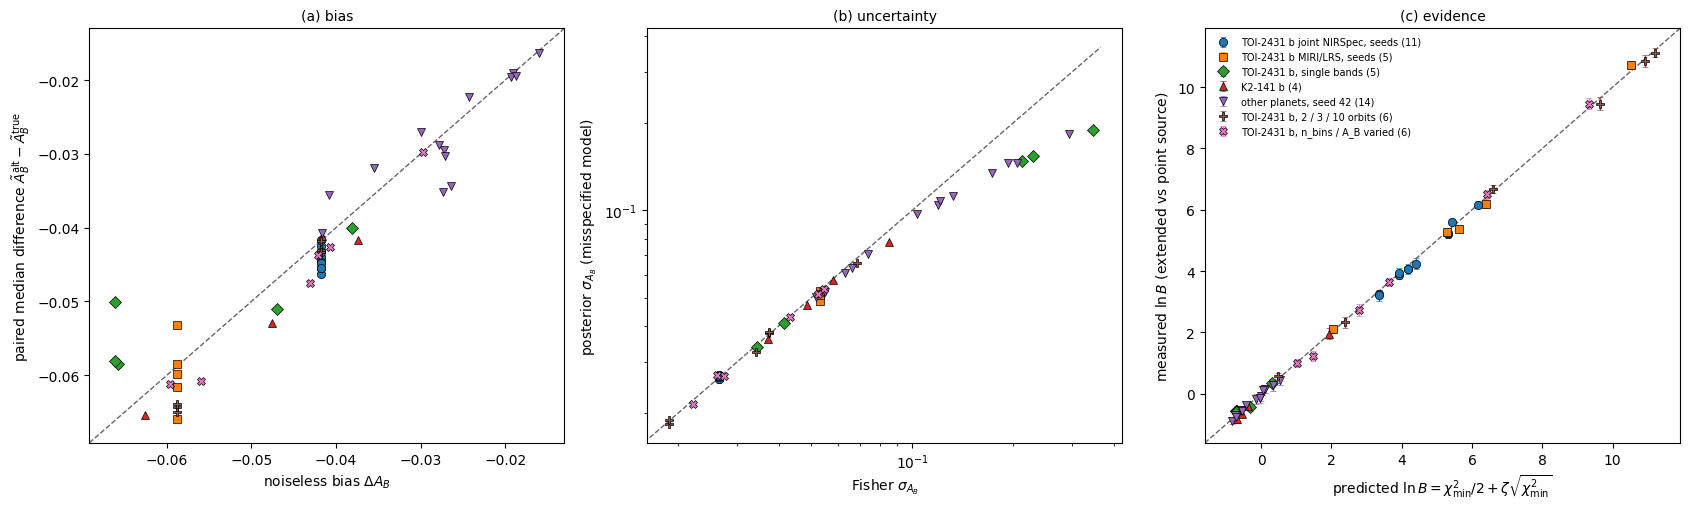

51 of 51 runs shown (null-test and free-geometry runs are compared with their own predictions in the last section)


In [6]:
PAPER_MODE = False
is_ = lambda name: (runs["series"] == name).to_numpy()
normal = (runs["kind"] == "").to_numpy()
ref_T = normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] == 5).to_numpy() & (runs["n_bins"] == 27).to_numpy() & (runs["A_B_true"] == 0.2).to_numpy()
GROUPS = {"TOI-2431 b joint NIRSpec, seeds": ref_T & (runs["mode"] == "joint NIRSpec").to_numpy(),
          "TOI-2431 b MIRI/LRS, seeds": ref_T & (runs["mode"] == "MIRI/LRS").to_numpy(),
          "TOI-2431 b, single bands": ref_T & ~runs["mode"].isin(["joint NIRSpec", "MIRI/LRS", "NIRSpec + LRS"]).to_numpy(),
          "K2-141 b": normal & (runs["planet"] == K).to_numpy() & (runs["mode"] != "NIRSpec + LRS").to_numpy(),
          "other planets, seed 42": normal & ~runs["planet"].isin([T, K]).to_numpy(),
          "TOI-2431 b, 2 / 3 / 10 orbits": normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] != 5).to_numpy(),
          "TOI-2431 b, n_bins / A_B varied": normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] == 5).to_numpy() & ((runs["n_bins"] != 27) | (runs["A_B_true"] != 0.2)).to_numpy(),
          "three detectors": normal & (runs["mode"] == "NIRSpec + LRS").to_numpy()}
shown = np.any(list(GROUPS.values()), axis=0)
fig, axes = plot_ns_check(runs, groups=GROUPS)
paper_figure("ns_check", PAPER_MODE, fig=fig)
plt.show()
print(f"{int(shown.sum())} of {len(runs)} runs shown (null-test and free-geometry runs are compared with their own predictions in the last section)")

## 4. Same seed, other number of orbits

`simulate_data` draws the noise as $\sigma_{\rm bin}\,z$ from `default_rng(seed)`, so one seed gives the same $z$ for any number of orbits, and $\sigma_{\rm bin} \propto 1/\sqrt{n_{\rm orbits}}$. Runs of the same planet, mode and seed therefore share $\zeta$, and the likelihood-ratio statistic at $n$ orbits follows from the 5-orbit numbers alone:
$$2\,\Delta\ln\mathcal{L}_{\max}(n) = \tfrac{n}{5}\chi^2_{\min} + 2\zeta\sqrt{\tfrac{n}{5}\chi^2_{\min}} .$$
The cell pairs every run at another number of orbits with the baseline run of the same seed and compares the scaled prediction with the measured $2\,\Delta\ln\mathcal{L}_{\max}$ and $\ln B$.

What to look for: the shared $\zeta$ (the two `zeta` columns agree), and the scaled prediction against the measurement.

In [7]:
key = ["planet", "mode", "seed"]
five = runs[(runs["kind"] == "") & (runs["n_orbits"] == 5) & (runs["n_bins"] == 27) & (runs["A_B_true"] == 0.2)].sort_values("pfrac").drop_duplicates(key, keep="last").set_index(key)   # the pfrac 0.8 / 1 run where a seed has several
rows = []
for _, r in runs[(runs["kind"] == "") & (runs["n_orbits"] != 5)].iterrows():
    k = (r["planet"], r["mode"], r["seed"])
    if k not in five.index: rows.append(dict(planet=k[0], mode=k[1], seed=k[2], n_orbits=r["n_orbits"], note="no 5-orbit run of this seed")); continue
    b = five.loc[k]
    c = r["n_orbits"] / 5. * b["chi2_min"]
    rows.append(dict(planet=k[0], mode=k[1], seed=k[2], n_orbits=r["n_orbits"], zeta_5=b["zeta"], zeta_n=r["zeta"], dchi2_scaled=c + 2. * b["zeta"] * np.sqrt(c), dchi2_measured=2. * r["dlnL_max"],
                     lnB_scaled=0.5 * c + b["zeta"] * np.sqrt(c), lnB_measured=r["lnB"], lnB_err=r["lnB_err_jitter"]))
print(pd.DataFrame(rows).sort_values(["planet", "mode", "seed", "n_orbits"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if rows else "no run at another number of orbits yet")

    planet          mode  seed  n_orbits  zeta_5  zeta_n  dchi2_scaled  dchi2_measured  lnB_scaled  lnB_measured  lnB_err
TOI-2431 b      MIRI/LRS    42         3   -1.21   -1.21         0.942            1.05       0.471         0.566    0.112
TOI-2431 b      MIRI/LRS    42        10   -1.21   -1.21          13.2            13.3         6.6          6.69    0.133
TOI-2431 b      MIRI/LRS    43        10  -0.298  -0.298          22.4            22.3        11.2          11.1    0.143
TOI-2431 b joint NIRSpec    42         3  -0.413  -0.413           4.8            4.89         2.4          2.33    0.188
TOI-2431 b joint NIRSpec    42        10  -0.413  -0.413          19.3            19.4        9.65          9.46      0.2
TOI-2431 b joint NIRSpec    43        10  -0.149  -0.149          21.9            21.8        10.9          10.9    0.188


## 5. Measured only: the point-source model with redistribution, and the two pfrac

**Fits with redistribution.** For every run with a `naive_redist` fit: $\ln B$ of the truth's model against it, $\ln B$ of the point-source model with against without redistribution, and the posterior of $F$ (median, half-width of the 16-84 % interval, 95 % upper limit). No prediction: the prior of $F$ contributes an Occam term of about 3 nats and the posterior of $F$ is one-sided. The noiseless context ($\chi^2/2$ of that fit, the likelihood part) is in `Evidence_Prediction.ipynb`, section 2.

**pfrac.** Where the same data were sampled at two pfrac, the differences of $\ln B$ and of the $A_B$ posterior between the two runs, to judge whether the weighting of the sampler matters at the precision needed here.

In [8]:
red = runs[runs["lnB_vs_redist"].notna()] if "lnB_vs_redist" in runs else runs.iloc[:0]
cols = ["planet", "mode", "kind", "A_B_true", "n_bins", "n_orbits", "seed", "pfrac", "lnB_ext_vs_ps", "lnB_vs_redist", "lnB_redist_vs_ps", "F_med", "F_sigma", "F_95"]
print(red.assign(F_ratio=red["F_med"] / red["F_sigma"])[cols + ["F_ratio"]].sort_values(["kind", "planet", "mode", "A_B_true", "n_bins", "n_orbits", "seed", "pfrac"]).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

# the same data (planet, mode, settings, seed) at two pfrac
same = ["planet", "mode", "kind", "A_B_true", "n_bins", "n_orbits", "seed"]
pairs = []
for k, g in runs.groupby(same):
    if g["pfrac"].nunique() < 2: continue
    g = g.sort_values("pfrac")
    a, b = g.iloc[0], g.iloc[-1]
    pairs.append(dict(zip(same, k), pfrac_a=a["pfrac"], pfrac_b=b["pfrac"], d_lnB=b["lnB"] - a["lnB"], d_lnB_vs_redist=b["lnB_vs_redist"] - a["lnB_vs_redist"],
                      d_A_B_med_ps=b["A_B_med_alt"] - a["A_B_med_alt"], d_sigma_post=b["sigma_post"] - a["sigma_post"]))
print("\nsame data at two pfrac (b - a):")
print(pd.DataFrame(pairs).drop(columns=["kind", "A_B_true", "n_bins", "n_orbits"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if pairs else "   no dataset sampled at two pfrac")

     planet          mode kind  A_B_true  n_bins  n_orbits  seed  pfrac  lnB_ext_vs_ps  lnB_vs_redist  lnB_redist_vs_ps   F_med  F_sigma    F_95  F_ratio
 HD 80653 b      MIRI/LRS            0.2      27         5    42    0.8         -0.752           4.16             -4.92 0.00221  0.00237 0.00828    0.933
 HD 80653 b joint NIRSpec            0.2      27         5    42    0.8          0.128           3.59             -3.46 0.00523  0.00465  0.0152     1.13
   K2-131 b      MIRI/LRS            0.2      27         5    42    0.8         -0.519           3.63             -4.15 0.00492  0.00576  0.0208    0.853
   K2-131 b joint NIRSpec            0.2      27         5    42    0.8          0.157            3.8             -3.64 0.00719  0.00634  0.0213     1.13
   K2-141 b      MIRI/LRS            0.2      27         5    42    0.8         -0.391           4.06             -4.45 0.00259  0.00214 0.00738     1.21
   K2-141 b          NRS1            0.2      27         5    42    0.8     